# Task 5 — Sales Prediction Using Advertising Spend

Predict sales from TV, Radio and Newspaper advertising. Uses the classic 200-row Advertising dataset. Its media-spend and sales units are the source dataset’s original units, not Indian rupees.

In [1]:
# If needed: %pip install pandas numpy matplotlib seaborn scikit-learn requests
from pathlib import Path
import requests,numpy as np,pandas as pd,matplotlib.pyplot as plt,seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error,mean_squared_error,r2_score
RANDOM_STATE=42; sns.set_theme(style='whitegrid')

## 1. Download and load dataset

In [2]:
data_dir=Path('data'); data_dir.mkdir(exist_ok=True); data_file=data_dir/'Advertising.csv'
url='https://raw.githubusercontent.com/selva86/datasets/master/Advertising.csv'
if not data_file.exists():
 r=requests.get(url,timeout=60); r.raise_for_status(); data_file.write_bytes(r.content)
df=pd.read_csv(data_file); df=df.loc[:,~df.columns.str.contains('^Unnamed',case=False)]
# Normalise column names to match expected: TV, Radio, Newspaper, Sales
col_map = {c: c.strip().title() for c in df.columns}
col_map.update({k: v for k,v in col_map.items() if v.lower()=='tv'})
df.columns = [('TV' if c.strip().lower()=='tv' else c.strip().title()) for c in df.columns]
print('Shape:',df.shape); print('Columns:',df.columns.tolist()); display(df.head())


Shape: (200, 4)
Columns: ['TV', 'Radio', 'Newspaper', 'Sales']


,TV,Radio,Newspaper,Sales
0,230.1,37.8,69.2,22.1
1,44.5,39.3,45.1,10.4
2,17.2,45.9,69.3,9.3
3,151.5,41.3,58.5,18.5
4,180.8,10.8,58.4,12.9


## 2. Data quality and descriptive statistics

In [3]:
print(df.dtypes); print('Nulls:\n',df.isna().sum()); print('Duplicates:',df.duplicated().sum()); display(df.describe().T)
expected={'TV','Radio','Newspaper','Sales'}; assert expected.issubset(df.columns),f'Expected columns {expected}; found {set(df.columns)}'

TV           float64
Radio        float64
Newspaper    float64
Sales        float64
dtype: object
Nulls:
 TV           0
Radio        0
Newspaper    0
Sales        0
dtype: int64
Duplicates: 0


,count,mean,std,min,25%,50%,75%,max
TV,200.0,147.0425,85.854236,0.7,74.375,149.75,218.825,296.4
Radio,200.0,23.2640,14.846809,0.0,9.975,22.90,36.525,49.6
Newspaper,200.0,30.5540,21.778621,0.3,12.750,25.75,45.100,114.0
Sales,200.0,14.0225,5.217457,1.6,10.375,12.90,17.400,27.0


## 3. Exploratory data analysis

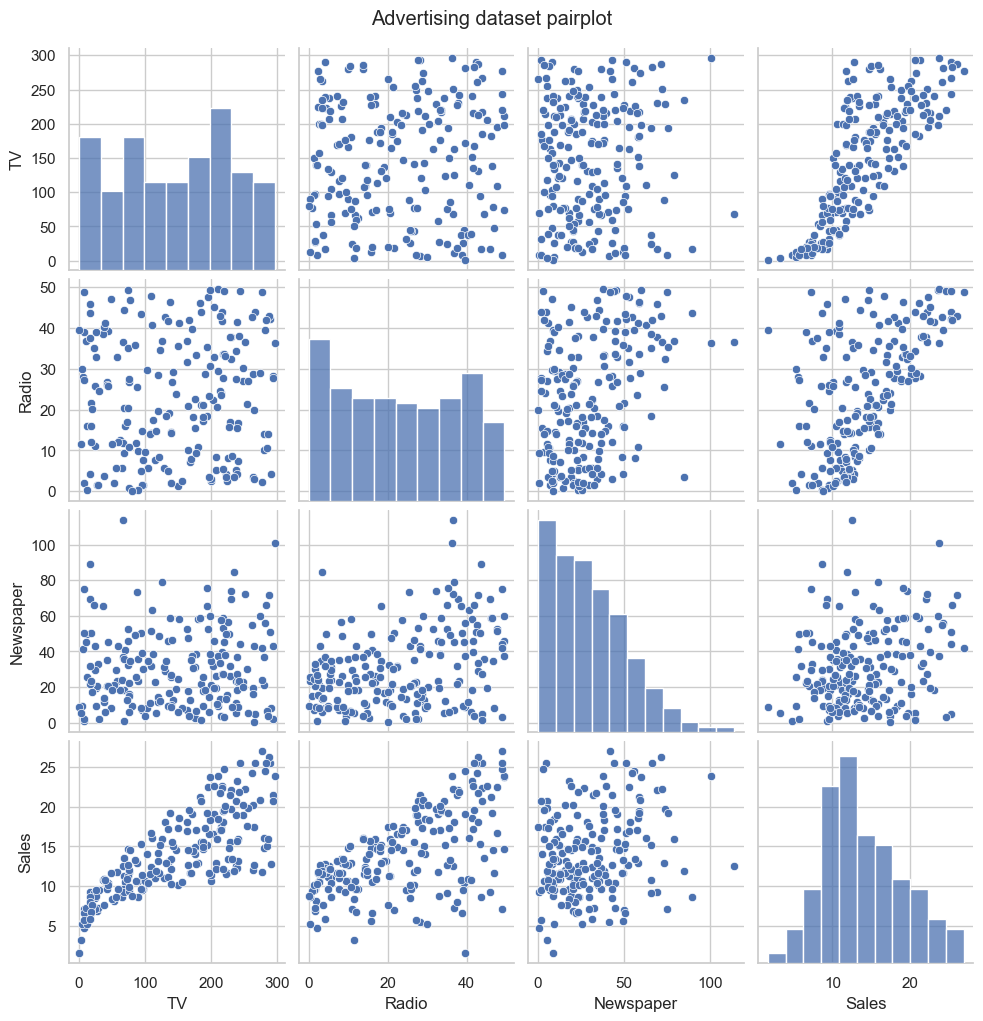

In [4]:
sns.pairplot(df,diag_kind='hist'); plt.suptitle('Advertising dataset pairplot',y=1.02); plt.show()

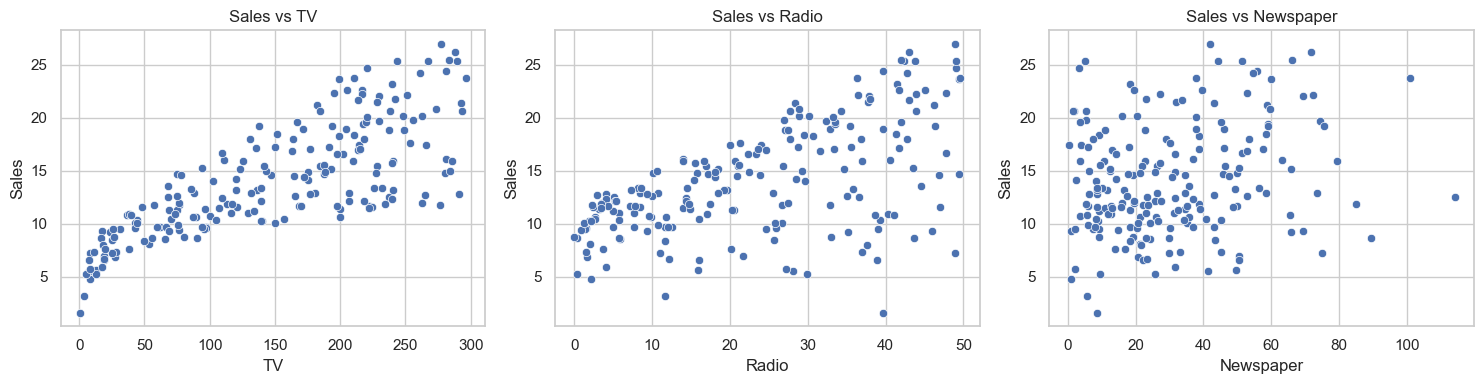

In [5]:
fig,axes=plt.subplots(1,3,figsize=(15,4))
for ax,f in zip(axes,['TV','Radio','Newspaper']): sns.scatterplot(data=df,x=f,y='Sales',ax=ax); ax.set_title(f'Sales vs {f}')
plt.tight_layout(); plt.show()

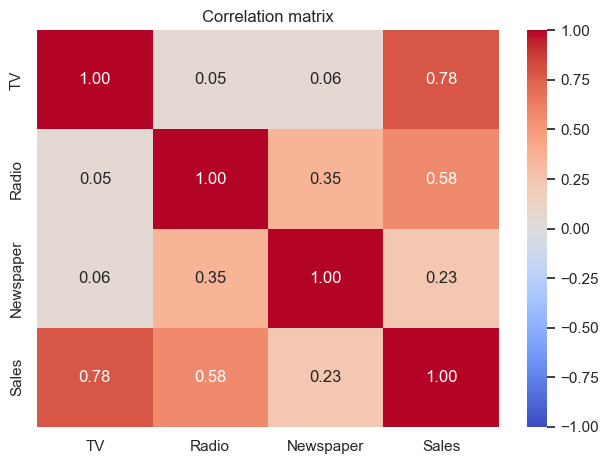

In [6]:
sns.heatmap(df.corr(numeric_only=True),annot=True,cmap='coolwarm',fmt='.2f',vmin=-1,vmax=1); plt.title('Correlation matrix'); plt.tight_layout(); plt.show()

**EDA interpretation:** In this classic dataset, TV and Radio tend to have clearer positive relationships with Sales than Newspaper. Correlation is association, not proof of causation.

## 4. Train/test split and regression models

In [7]:
features=['TV','Radio','Newspaper']; X=df[features]; y=df['Sales']
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=.2,random_state=RANDOM_STATE)
models={'Linear Regression':LinearRegression(),'Random Forest':RandomForestRegressor(n_estimators=400,min_samples_leaf=2,random_state=RANDOM_STATE)}
fitted={}; rows=[]
for name,model in models.items():
 model.fit(X_train,y_train); pred=model.predict(X_test); fitted[name]=model
 rows.append({'Model':name,'MAE':mean_absolute_error(y_test,pred),'RMSE':np.sqrt(mean_squared_error(y_test,pred)),'R2':r2_score(y_test,pred)})
results=pd.DataFrame(rows).sort_values(['RMSE','MAE']); display(results)

,Model,MAE,RMSE,R2
1,Random Forest,0.658817,0.791892,0.980132
0,Linear Regression,1.460757,1.781600,0.899438


## 5. Model comparison

MAE is average absolute error; RMSE penalizes large errors more strongly; R² compares explained variance with a mean-prediction baseline. Lower MAE/RMSE and higher R² are generally preferable. We select the model with lowest held-out RMSE (MAE tie-breaker).

In [8]:
best_name=results.iloc[0]['Model']; best_model=fitted[best_name]; pred=best_model.predict(X_test); residuals=y_test-pred
print('Selected:',best_name); print('MAE:',mean_absolute_error(y_test,pred)); print('RMSE:',np.sqrt(mean_squared_error(y_test,pred))); print('R2:',r2_score(y_test,pred))

Selected: Random Forest
MAE: 0.6588170889700578
RMSE: 0.7918923661845925
R2: 0.9801323789493573


## 6. Residual diagnostics

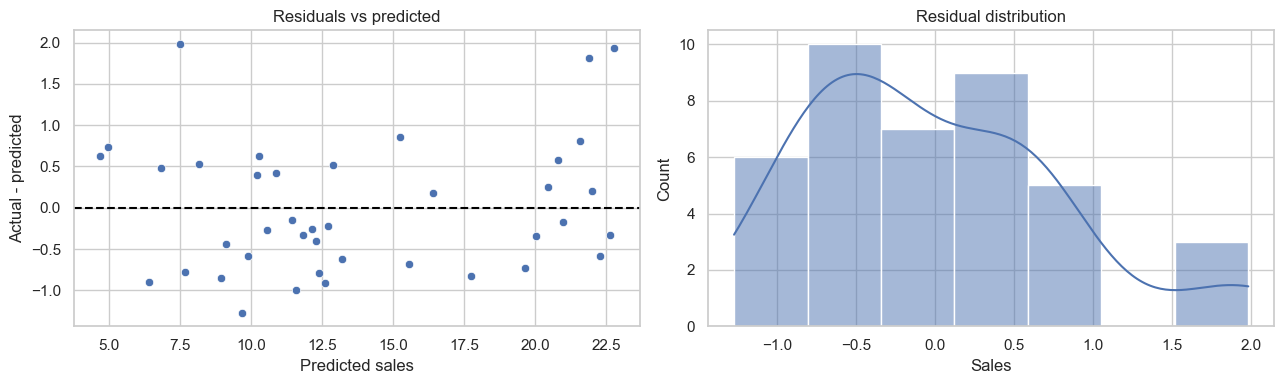

In [9]:
fig,axes=plt.subplots(1,2,figsize=(13,4)); sns.scatterplot(x=pred,y=residuals,ax=axes[0]); axes[0].axhline(0,ls='--',color='black'); axes[0].set(xlabel='Predicted sales',ylabel='Actual - predicted',title='Residuals vs predicted')
sns.histplot(residuals,kde=True,ax=axes[1]); axes[1].set_title('Residual distribution'); plt.tight_layout(); plt.show()

**Interpretation:** Ideally residuals are randomly scattered around zero. Curves may indicate a missing nonlinear pattern; a funnel shape may indicate changing error variance. Inspect outliers rather than assuming residuals must be perfectly normal.

## 7. Advertising channel impact

Linear Regression coefficients:


,Coefficient
Radio,0.189195
TV,0.044730
Newspaper,0.002761


,Importance
TV,0.629217
Radio,0.360787
Newspaper,0.009996


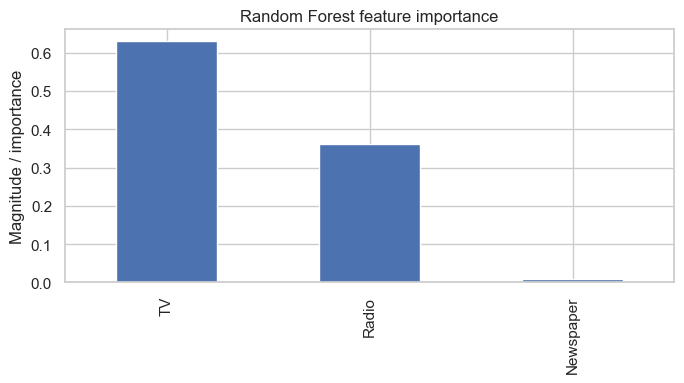

In [10]:
# Coefficients are interpretable marginal associations; RF importances are relative predictive contribution.
lin_coef=pd.Series(fitted['Linear Regression'].coef_,index=features).sort_values(ascending=False); print('Linear Regression coefficients:'); display(lin_coef.to_frame('Coefficient'))
if best_name=='Linear Regression': impact=lin_coef.abs().sort_values(ascending=False); title='Absolute linear coefficients'
else: impact=pd.Series(best_model.feature_importances_,index=features).sort_values(ascending=False); title='Random Forest feature importance'; display(impact.to_frame('Importance'))
impact.plot(kind='bar',title=title,figsize=(7,4)); plt.ylabel('Magnitude / importance'); plt.tight_layout(); plt.show()

Use linear coefficients to discuss direction and marginal association, holding other channels fixed. Random Forest importance describes predictive usefulness, not direction or causality. TV and Radio are generally more informative in this dataset.

## 8. Predict a hypothetical campaign

In [11]:
campaign=pd.DataFrame({'TV':[150],'Radio':[25],'Newspaper':[20]}); display(campaign); print('Predicted sales (source units):',best_model.predict(campaign)[0])

,TV,Radio,Newspaper
0,150,25,20


Predicted sales (source units): 15.228824305555568


## 9. Conclusion and limitations

The project includes EDA, two regressors, MAE/RMSE/R², residual plots and channel interpretation. The dataset is small and historical and omits pricing, seasonality, distribution, audience and competitor effects. Predictions are educational estimates, not guaranteed outcomes or causal claims.